In [ ]:
from google.colab import files

uploaded = files.upload()

Saving applicants_cleaned.csv to applicants_cleaned (1).csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "applicants_cleaned.csv",
    parse_dates=["Application Date"]
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset Shape: (58, 7)


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Ali Khan,applicant1@example.com,3.001000e+09,Web Development,Abc University,2026-01-01,Approved
1,Ahmed Raza,applicant2@example.com,3.001000e+09,Data Science,Xyz University,2026-01-02,Pending
2,Sara Ahmed,applicant3@example.com,3.001000e+09,Cyber Security,City University,2026-01-03,Under Review
3,Usman Malik,applicant4@example.com,3.001000e+09,App Development,National University,2026-01-04,Rejected
4,Ayesha Noor,applicant5@example.com,3.001000e+09,UI/UX Design,Tech University,2026-01-05,Approved



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    58 non-null     object        
 1   Email             58 non-null     object        
 2   Phone             57 non-null     float64       
 3   Domain Applied    58 non-null     object        
 4   University        58 non-null     object        
 5   Application Date  57 non-null     datetime64[ns]
 6   Status            58 non-null     object        
dtypes: datetime64[ns](1), float64(1), object(5)
memory usage: 3.3+ KB

Missing Values:
Applicant Name      0
Email               0
Phone               1
Domain Applied      0
University          0
Application Date    1
Status              0
dtype: int64


Day 1: Dataset Setup and Initial Exploration

The cleaned applicant dataset was successfully loaded into Pandas.

- Total records: 58
- Total columns: 7
- Date data type: datetime64[ns]
- Missing phone numbers: 1
- Missing application dates: 1

The dataset contains applicant details, applied domains, universities, application dates, and application statuses. The dataset is ready for exploratory data analysis, with missing values considered during interpretation.

In [ ]:
domain_counts = df["Domain Applied"].value_counts()

print("Applications by Domain:")
print(domain_counts)

Applications by Domain:
Domain Applied
Web Development    14
Data Science       12
Cyber Security     11
App Development    11
UI/UX Design       10
Name: count, dtype: int64


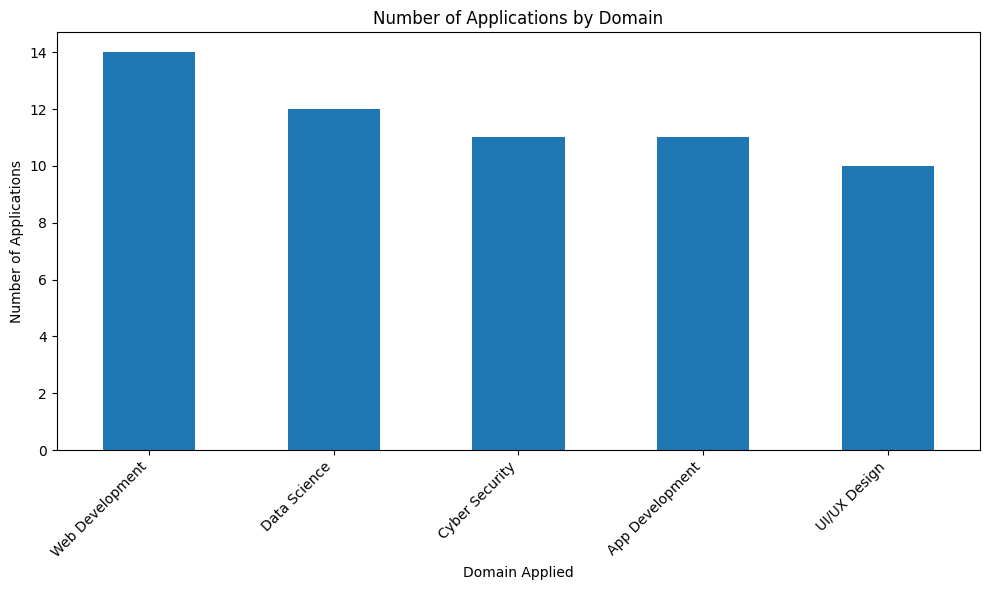

In [ ]:
plt.figure(figsize=(10, 6))

domain_counts.plot(kind="bar")

plt.title("Number of Applications by Domain")
plt.xlabel("Domain Applied")
plt.ylabel("Number of Applications")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Finding: Applications by Domain

Web Development received the highest number of applications, with 14 applications. Data Science followed with 12 applications, while Cyber Security and App Development each received 11 applications. UI/UX Design received the lowest number, with 10 applications.

In [ ]:
df["Application Month"] = df["Application Date"].dt.to_period("M")

monthly_applications = df.groupby("Application Month").size()

print("Applications by Month:")
print(monthly_applications)

Applications by Month:
Application Month
2026-01    57
Freq: M, dtype: int64


/usr/local/lib/python3.13/dist-packages/pandas/plotting/_matplotlib/core.py:1567: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


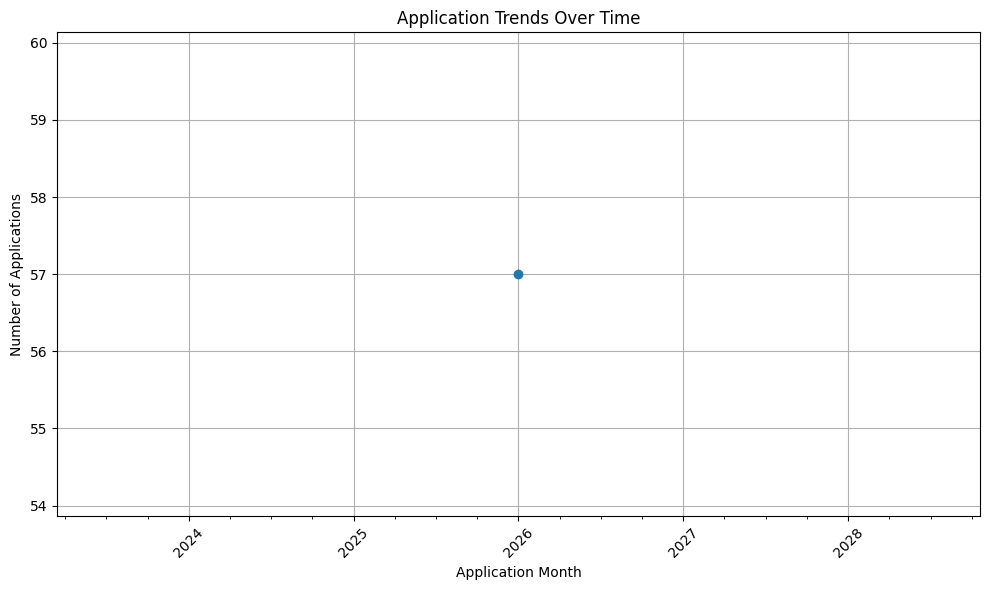

In [ ]:
plt.figure(figsize=(10, 6))

monthly_applications.plot(kind="line", marker="o")

plt.title("Application Trends Over Time")
plt.xlabel("Application Month")
plt.ylabel("Number of Applications")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

Finding: Application Trends Over Time

The dataset contains 57 applications with valid application dates, all recorded in January 2026. Since the available dates cover only one month, a trend across multiple months cannot be determined from this dataset.

In [ ]:
status_counts = df["Status"].value_counts()

print("Application Status Breakdown:")
print(status_counts)

Application Status Breakdown:
Status
Approved        15
Pending         15
Under Review    15
Rejected        13
Name: count, dtype: int64


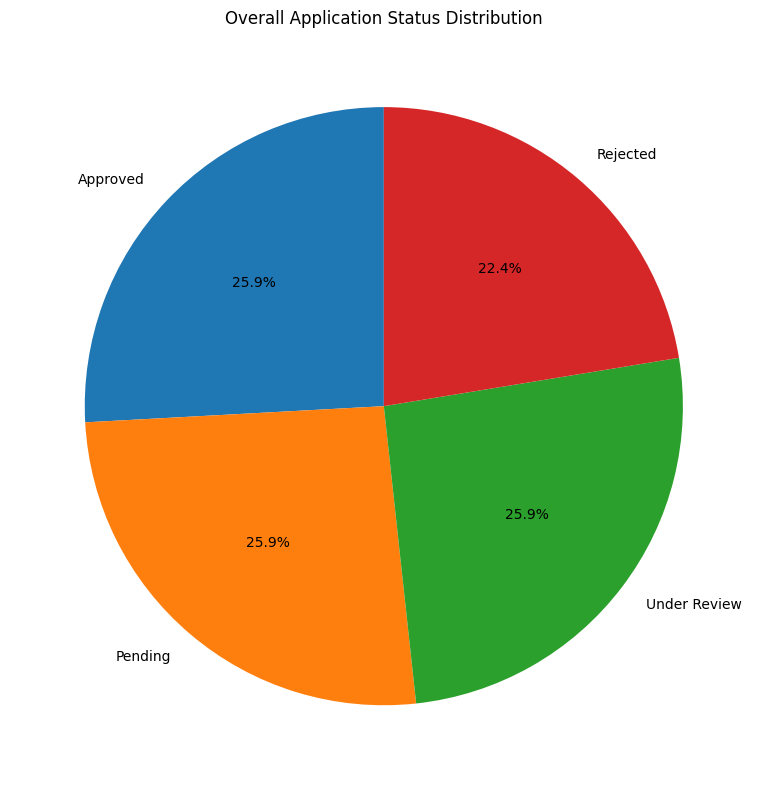

In [ ]:
plt.figure(figsize=(8, 8))

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Overall Application Status Distribution")
plt.tight_layout()
plt.show()

Finding: Overall Application Status Distribution

Approved, Pending, and Under Review each account for 15 applications (approximately 25.9% each). Rejected applications account for 13 records (approximately 22.4%). The dataset contains 58 applications in total.

In [ ]:
status_by_domain = pd.pivot_table(
    df,
    index="Domain Applied",
    columns="Status",
    values="Applicant Name",
    aggfunc="count",
    fill_value=0
)

print(status_by_domain)

Status           Approved  Pending  Rejected  Under Review
Domain Applied                                            
App Development         3        2         4             2
Cyber Security          2        2         3             4
Data Science            3        3         2             4
UI/UX Design            3        3         2             2
Web Development         4        5         2             3


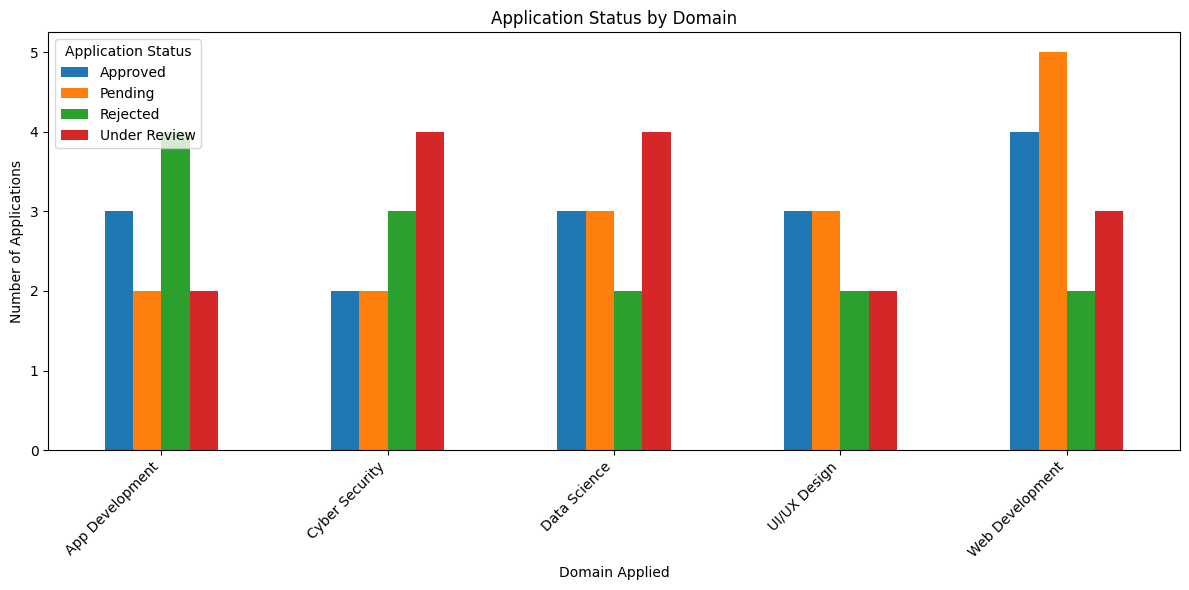

In [ ]:
status_by_domain.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Application Status by Domain")
plt.xlabel("Domain Applied")
plt.ylabel("Number of Applications")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Application Status")
plt.tight_layout()
plt.show()

Finding: Application Status by Domain

Web Development has the highest number of Pending applications (5) and Approved applications (4). Cyber Security and Data Science each have 4 applications Under Review. App Development has the highest number of Rejected applications (4). These are raw counts, not approval rates.

In [ ]:

status_by_domain_pct = (
    status_by_domain
    .div(status_by_domain.sum(axis=1), axis=0)
    * 100
)

approval_rates = status_by_domain_pct["Approved"]

print("Approval Rate by Domain (%):")
print(approval_rates.round(2))

Approval Rate by Domain (%):
Domain Applied
App Development    27.27
Cyber Security     18.18
Data Science       25.00
UI/UX Design       30.00
Web Development    28.57
Name: Approved, dtype: float64


Finding: Approval Rate by Domain

UI/UX Design has the highest approval rate at 30.00%, followed by Web Development at 28.57%. Cyber Security has the lowest approval rate at 18.18%. These percentages represent the share of applications marked Approved within each domain in this dataset.

In [ ]:
top_universities = df["University"].value_counts().head(10)

print("Top Universities by Number of Applications:")
print(top_universities)

Top Universities by Number of Applications:
University
Abc University         12
Xyz University         12
City University        11
National University    11
Tech University        11
Not Specified           1
Name: count, dtype: int64


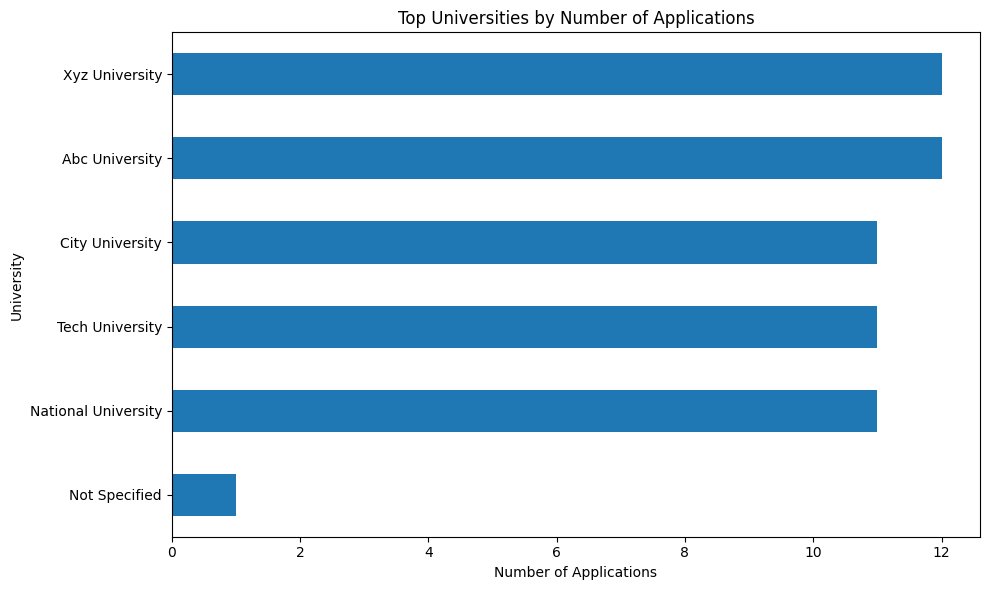

In [ ]:
plt.figure(figsize=(10, 6))

top_universities.sort_values().plot(kind="barh")

plt.title("Top Universities by Number of Applications")
plt.xlabel("Number of Applications")
plt.ylabel("University")

plt.tight_layout()
plt.show()

Finding: Applications by University

Abc University and Xyz University have the highest number of applications, with 12 each. City University, National University, and Tech University each have 11 applications. One application has no specified university, so it is recorded as "Not Specified."

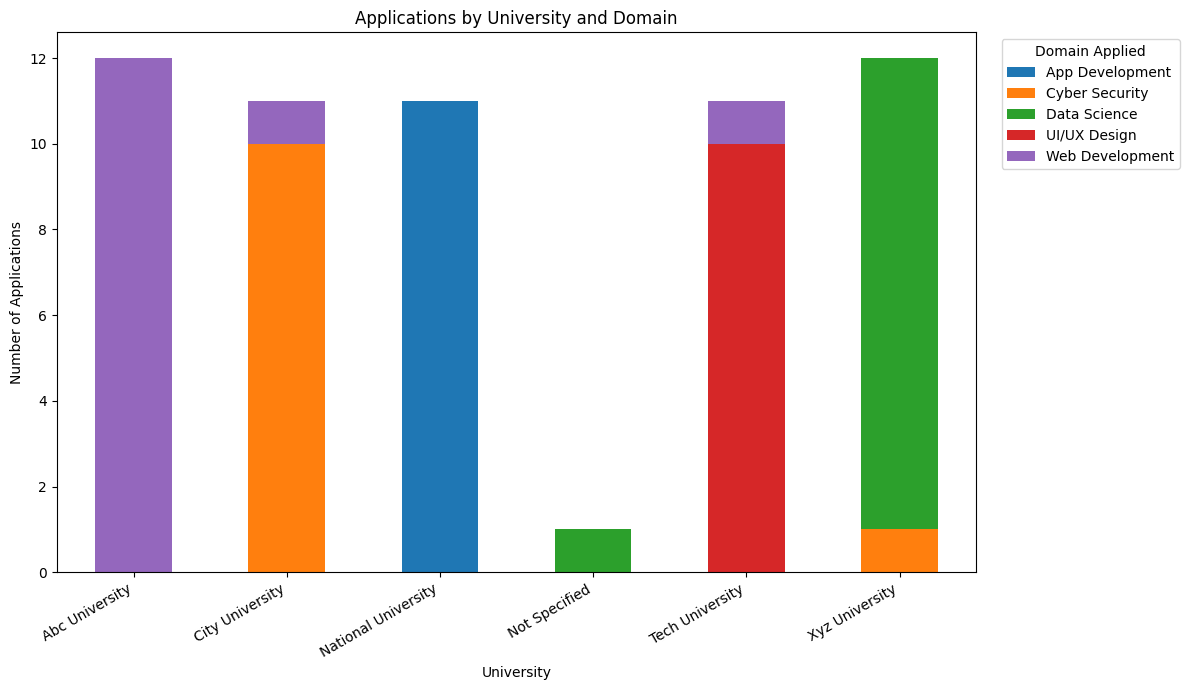

In [ ]:
domain_by_university.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

plt.title("Applications by University and Domain")
plt.xlabel("University")
plt.ylabel("Number of Applications")
plt.xticks(rotation=30, ha="right")
plt.legend(
    title="Domain Applied",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Bonus Analysis: Applications by University and Domain

This stacked bar chart compares the number of applications from each university across different domains. It helps identify how application counts are distributed among universities and domains.

Key Insights

1. Most popular domain: Web Development received the highest number of applications, with 14.
2. Application status: Approved, Pending, and Under Review each had 15 applications, while Rejected had 13.
3. Approval rate: UI/UX Design had the highest approval rate at 30.00%, while Cyber Security had the lowest at 18.18%.
4. Top universities: Abc University and Xyz University had the highest application counts, with 12 each.
5. Application dates: 57 applications had valid dates, all in January 2026. Therefore, the dataset does not support comparisons across multiple months.